In [ ]:
#11/23 작업

Mask: C:\Users\soyoo\URP_cdo_data\10~11\1115\common_spatial_mask.npy
Valid grid cells: 11856
Z-score directory: C:\Users\soyoo\URP_cdo_data\10~11\1118\PR_zscore_pooled5

===== SSP245 (5 members) =====
Loaded: PR_zscore_monthly_SSP245_r1.nc | valid values: 4,268,160
Loaded: PR_zscore_monthly_SSP245_r2.nc | valid values: 4,268,160
Loaded: PR_zscore_monthly_SSP245_r3.nc | valid values: 4,268,160
Loaded: PR_zscore_monthly_SSP245_r4.nc | valid values: 4,268,160
Loaded: PR_zscore_monthly_SSP245_r5.nc | valid values: 4,268,160

===== SAI SCENARIOS =====

SAI 45N
Loaded: PR_zscore_monthly_45N_e02.nc | valid values: 4,268,160
Loaded: PR_zscore_monthly_45N_e03.nc | valid values: 4,268,160
Loaded: PR_zscore_monthly_45N_e04.nc | valid values: 4,268,160
Loaded: PR_zscore_monthly_45N_e05.nc | valid values: 4,268,160
Loaded: PR_zscore_monthly_45N_e06.nc | valid values: 4,268,160
Loaded: PR_zscore_monthly_45N_e07.nc | valid values: 4,268,160
SAI 45N: Z < -1 = 13.72%, outside plot = 0.27%

SAI 30N
Load

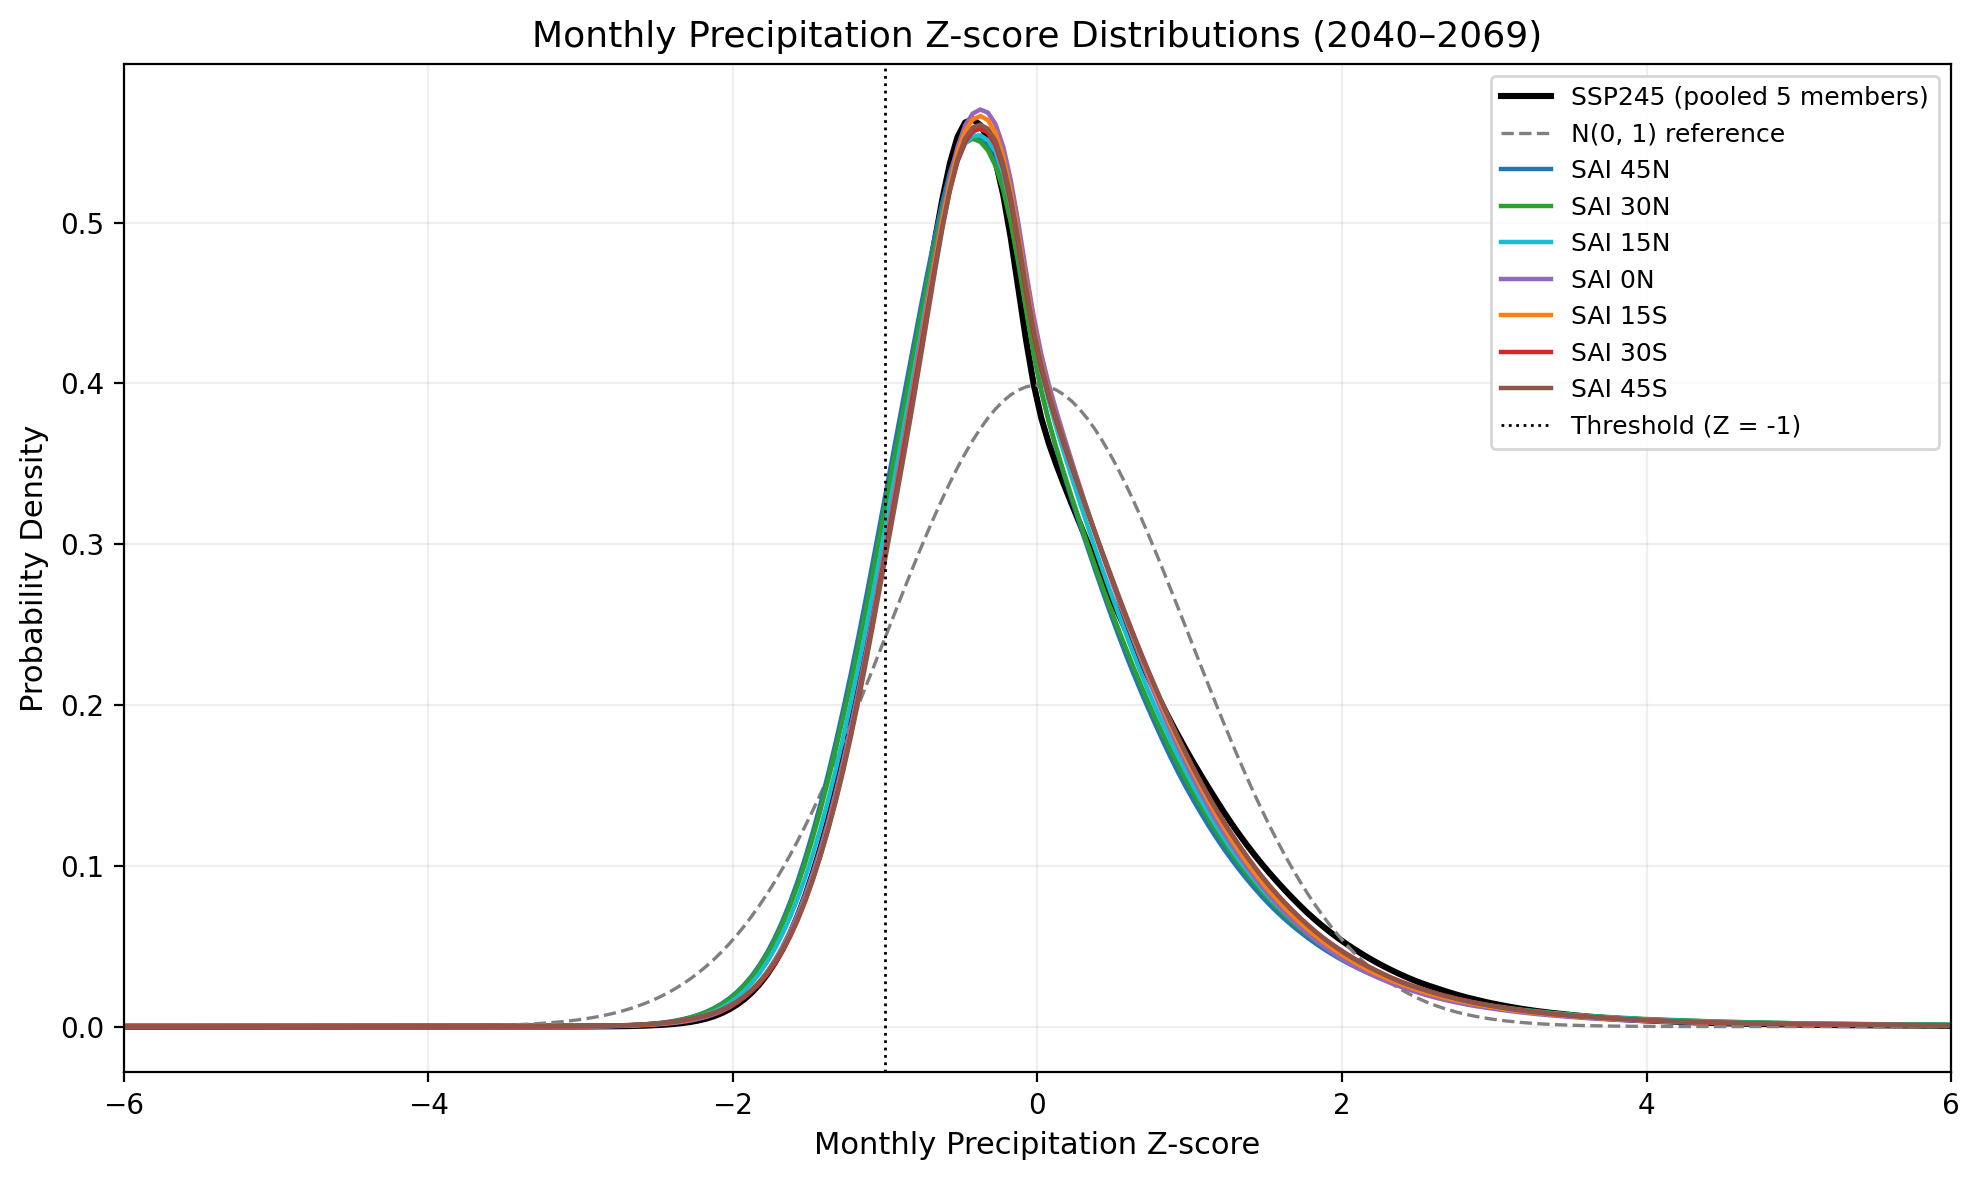


Saved: C:\Users\soyoo\URP_cdo_data\10~11\1118\PR_monthly_zscore_PDF_pooled5.png


In [15]:

from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm

# ==================================================
# 1. Settings
# ==================================================

BASE_DIR = Path(
    r"C:\Users\soyoo\URP_cdo_data\10~11\1118"
)

DATA_DIR = BASE_DIR / "PR_zscore_pooled5"

OUTPUT_PNG = BASE_DIR / "PR_monthly_zscore_PDF_pooled5.png"

scenarios = [
    "45N", "30N", "15N", "0N",
    "15S", "30S", "45S"
]

sai_members = [
    "e02", "e03", "e04",
    "e05", "e06", "e07"
]

ssp_members = [
    "r1", "r2", "r3", "r4", "r5"
]

palette = {
    "45N": "#1F77B4",
    "30N": "#2CA02C",
    "15N": "#17BECF",
    "0N":  "#9467BD",
    "15S": "#FF7F0E",
    "30S": "#D62728",
    "45S": "#8C564B",
}

XMIN = -6.0
XMAX = 6.0
BIN_WIDTH = 0.05
SMOOTH_SIGMA = 1.5

edges = np.arange(
    XMIN,
    XMAX + BIN_WIDTH / 2,
    BIN_WIDTH
)

centers = (
    edges[:-1] + edges[1:]
) / 2

# ==================================================
# 2. Load common spatial mask
# ==================================================

MASK_CANDIDATES = [
    BASE_DIR / "common_spatial_mask.npy",
    BASE_DIR.parent / "1115" / "common_spatial_mask.npy",
]

mask_path = next(
    (p for p in MASK_CANDIDATES if p.is_file()),
    None
)

if mask_path is None:
    raise FileNotFoundError(
        "common_spatial_mask.npy not found "
        "in 1118 or 1115."
    )

mask = np.load(mask_path).astype(bool)

if mask.shape != (192, 288):
    raise ValueError(
        f"Unexpected mask shape: {mask.shape}"
    )

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Data directory not found: {DATA_DIR}"
    )

print("Mask:", mask_path)
print("Valid grid cells:", mask.sum())
print("Z-score directory:", DATA_DIR)

# ==================================================
# 3. Read valid monthly z-score values
# ==================================================

def load_valid_values(path):

    if not path.is_file():
        raise FileNotFoundError(path)

    with xr.open_dataset(path) as ds:

        if "pr" not in ds.data_vars:
            raise ValueError(
                f"Variable 'pr' not found: {path}"
            )

        da = ds["pr"].transpose(
            "time", "lat", "lon"
        )

        if da.sizes["time"] != 360:
            raise ValueError(
                f"Expected 360 months: {path}"
            )

        if tuple(da.shape[1:]) != mask.shape:
            raise ValueError(
                f"Grid mismatch: {path}"
            )

        # Check calendar coverage
        expected_years = np.repeat(
            np.arange(2040, 2070), 12
        )
        expected_months = np.tile(
            np.arange(1, 13), 30
        )

        if not np.array_equal(
            da.time.dt.year.values,
            expected_years
        ):
            raise ValueError(
                f"Unexpected year sequence: {path}"
            )

        if not np.array_equal(
            da.time.dt.month.values,
            expected_months
        ):
            raise ValueError(
                f"Unexpected month sequence: {path}"
            )

        values = da.values[:, mask].copy()

    return values[np.isfinite(values)]

# ==================================================
# 4. Build pooled empirical PDF
# ==================================================

def build_pdf(paths):

    counts = np.zeros(
        len(edges) - 1,
        dtype=np.float64
    )

    total = 0
    below_minus_one = 0
    outside_plot = 0

    for path in paths:

        values = load_valid_values(path)

        hist, _ = np.histogram(
            values,
            bins=edges
        )

        counts += hist

        total += values.size

        below_minus_one += np.count_nonzero(
            values < -1.0
        )

        outside_plot += np.count_nonzero(
            (values < XMIN) | (values > XMAX)
        )

        print(
            f"Loaded: {path.name} | "
            f"valid values: {values.size:,}"
        )

    if total == 0:
        raise ValueError(
            "No valid PR observations found."
        )

    # Normalize using ALL valid values,
    # including observations outside display range.
    density = counts / (
        total * BIN_WIDTH
    )

    # Visualization smoothing only
    density = gaussian_filter1d(
        density,
        sigma=SMOOTH_SIGMA
    )

    pct_low = (
        100.0 * below_minus_one / total
    )

    pct_outside = (
        100.0 * outside_plot / total
    )

    return density, pct_low, pct_outside

# ==================================================
# 5. SSP245 pooled empirical distribution
# ==================================================

ssp_paths = [
    DATA_DIR / (
        f"PR_zscore_monthly_SSP245_{member}.nc"
    )
    for member in ssp_members
]

print("\n===== SSP245 (5 members) =====")

ssp_density, ssp_low, ssp_tail = build_pdf(
    ssp_paths
)

# ==================================================
# 6. Plot
# ==================================================

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=200
)

ax.plot(
    centers,
    ssp_density,
    color="black",
    linewidth=2.2,
    label="SSP245 (pooled 5 members)"
)

# Standard normal: reference only
ax.plot(
    centers,
    norm.pdf(centers),
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="N(0, 1) reference"
)

# ==================================================
# 7. SAI scenario PDFs
# ==================================================

print("\n===== SAI SCENARIOS =====")

for scenario in scenarios:

    print(f"\nSAI {scenario}")

    scenario_paths = [
        DATA_DIR / (
            f"PR_zscore_monthly_{scenario}_{member}.nc"
        )
        for member in sai_members
    ]

    density, low, tail = build_pdf(
        scenario_paths
    )

    ax.plot(
        centers,
        density,
        color=palette[scenario],
        linewidth=1.6,
        label=f"SAI {scenario}"
    )

    print(
        f"SAI {scenario}: "
        f"Z < -1 = {low:.2f}%, "
        f"outside plot = {tail:.2f}%"
    )

print(
    f"\nSSP245: "
    f"Z < -1 = {ssp_low:.2f}%, "
    f"outside plot = {ssp_tail:.2f}%"
)

# ==================================================
# 8. Formatting
# ==================================================

ax.axvline(
    -1.0,
    color="black",
    linestyle=":",
    linewidth=1.0,
    label="Threshold (Z = -1)"
)

ax.set_xlim(
    XMIN,
    XMAX
)

ax.set_xlabel(
    "Monthly Precipitation Z-score",
    fontsize=11
)

ax.set_ylabel(
    "Probability Density",
    fontsize=11
)

ax.set_title(
    "Monthly Precipitation Z-score Distributions "
    "(2040–2069)",
    fontsize=13
)

ax.grid(alpha=0.2)

ax.legend(
    fontsize=9,
    frameon=True
)

plt.tight_layout()

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", OUTPUT_PNG)


Mask: C:\Users\soyoo\URP_cdo_data\10~11\1115\common_spatial_mask.npy
Valid grid cells: 11856
Z-score directory: C:\Users\soyoo\URP_cdo_data\10~11\1118\AET_zscore_pooled3

===== SSP245 (3 members) =====
Loaded: AET_zscore_monthly_SSP245_r1.nc | valid values: 4,268,160
Loaded: AET_zscore_monthly_SSP245_r2.nc | valid values: 4,268,160
Loaded: AET_zscore_monthly_SSP245_r3.nc | valid values: 4,268,160

===== SAI SCENARIOS =====

SAI 45N
Loaded: AET_zscore_monthly_45N_e02.nc | valid values: 4,268,160
Loaded: AET_zscore_monthly_45N_e03.nc | valid values: 4,268,160
Loaded: AET_zscore_monthly_45N_e04.nc | valid values: 4,268,160
Loaded: AET_zscore_monthly_45N_e05.nc | valid values: 4,268,160
Loaded: AET_zscore_monthly_45N_e06.nc | valid values: 4,268,160
Loaded: AET_zscore_monthly_45N_e07.nc | valid values: 4,268,160
SAI 45N (n=6 members): Z < -1 = 32.13%, outside plot = 1.57%

SAI 30N
Loaded: AET_zscore_monthly_30N_e02.nc | valid values: 4,268,160
Loaded: AET_zscore_monthly_30N_e03.nc | valid 

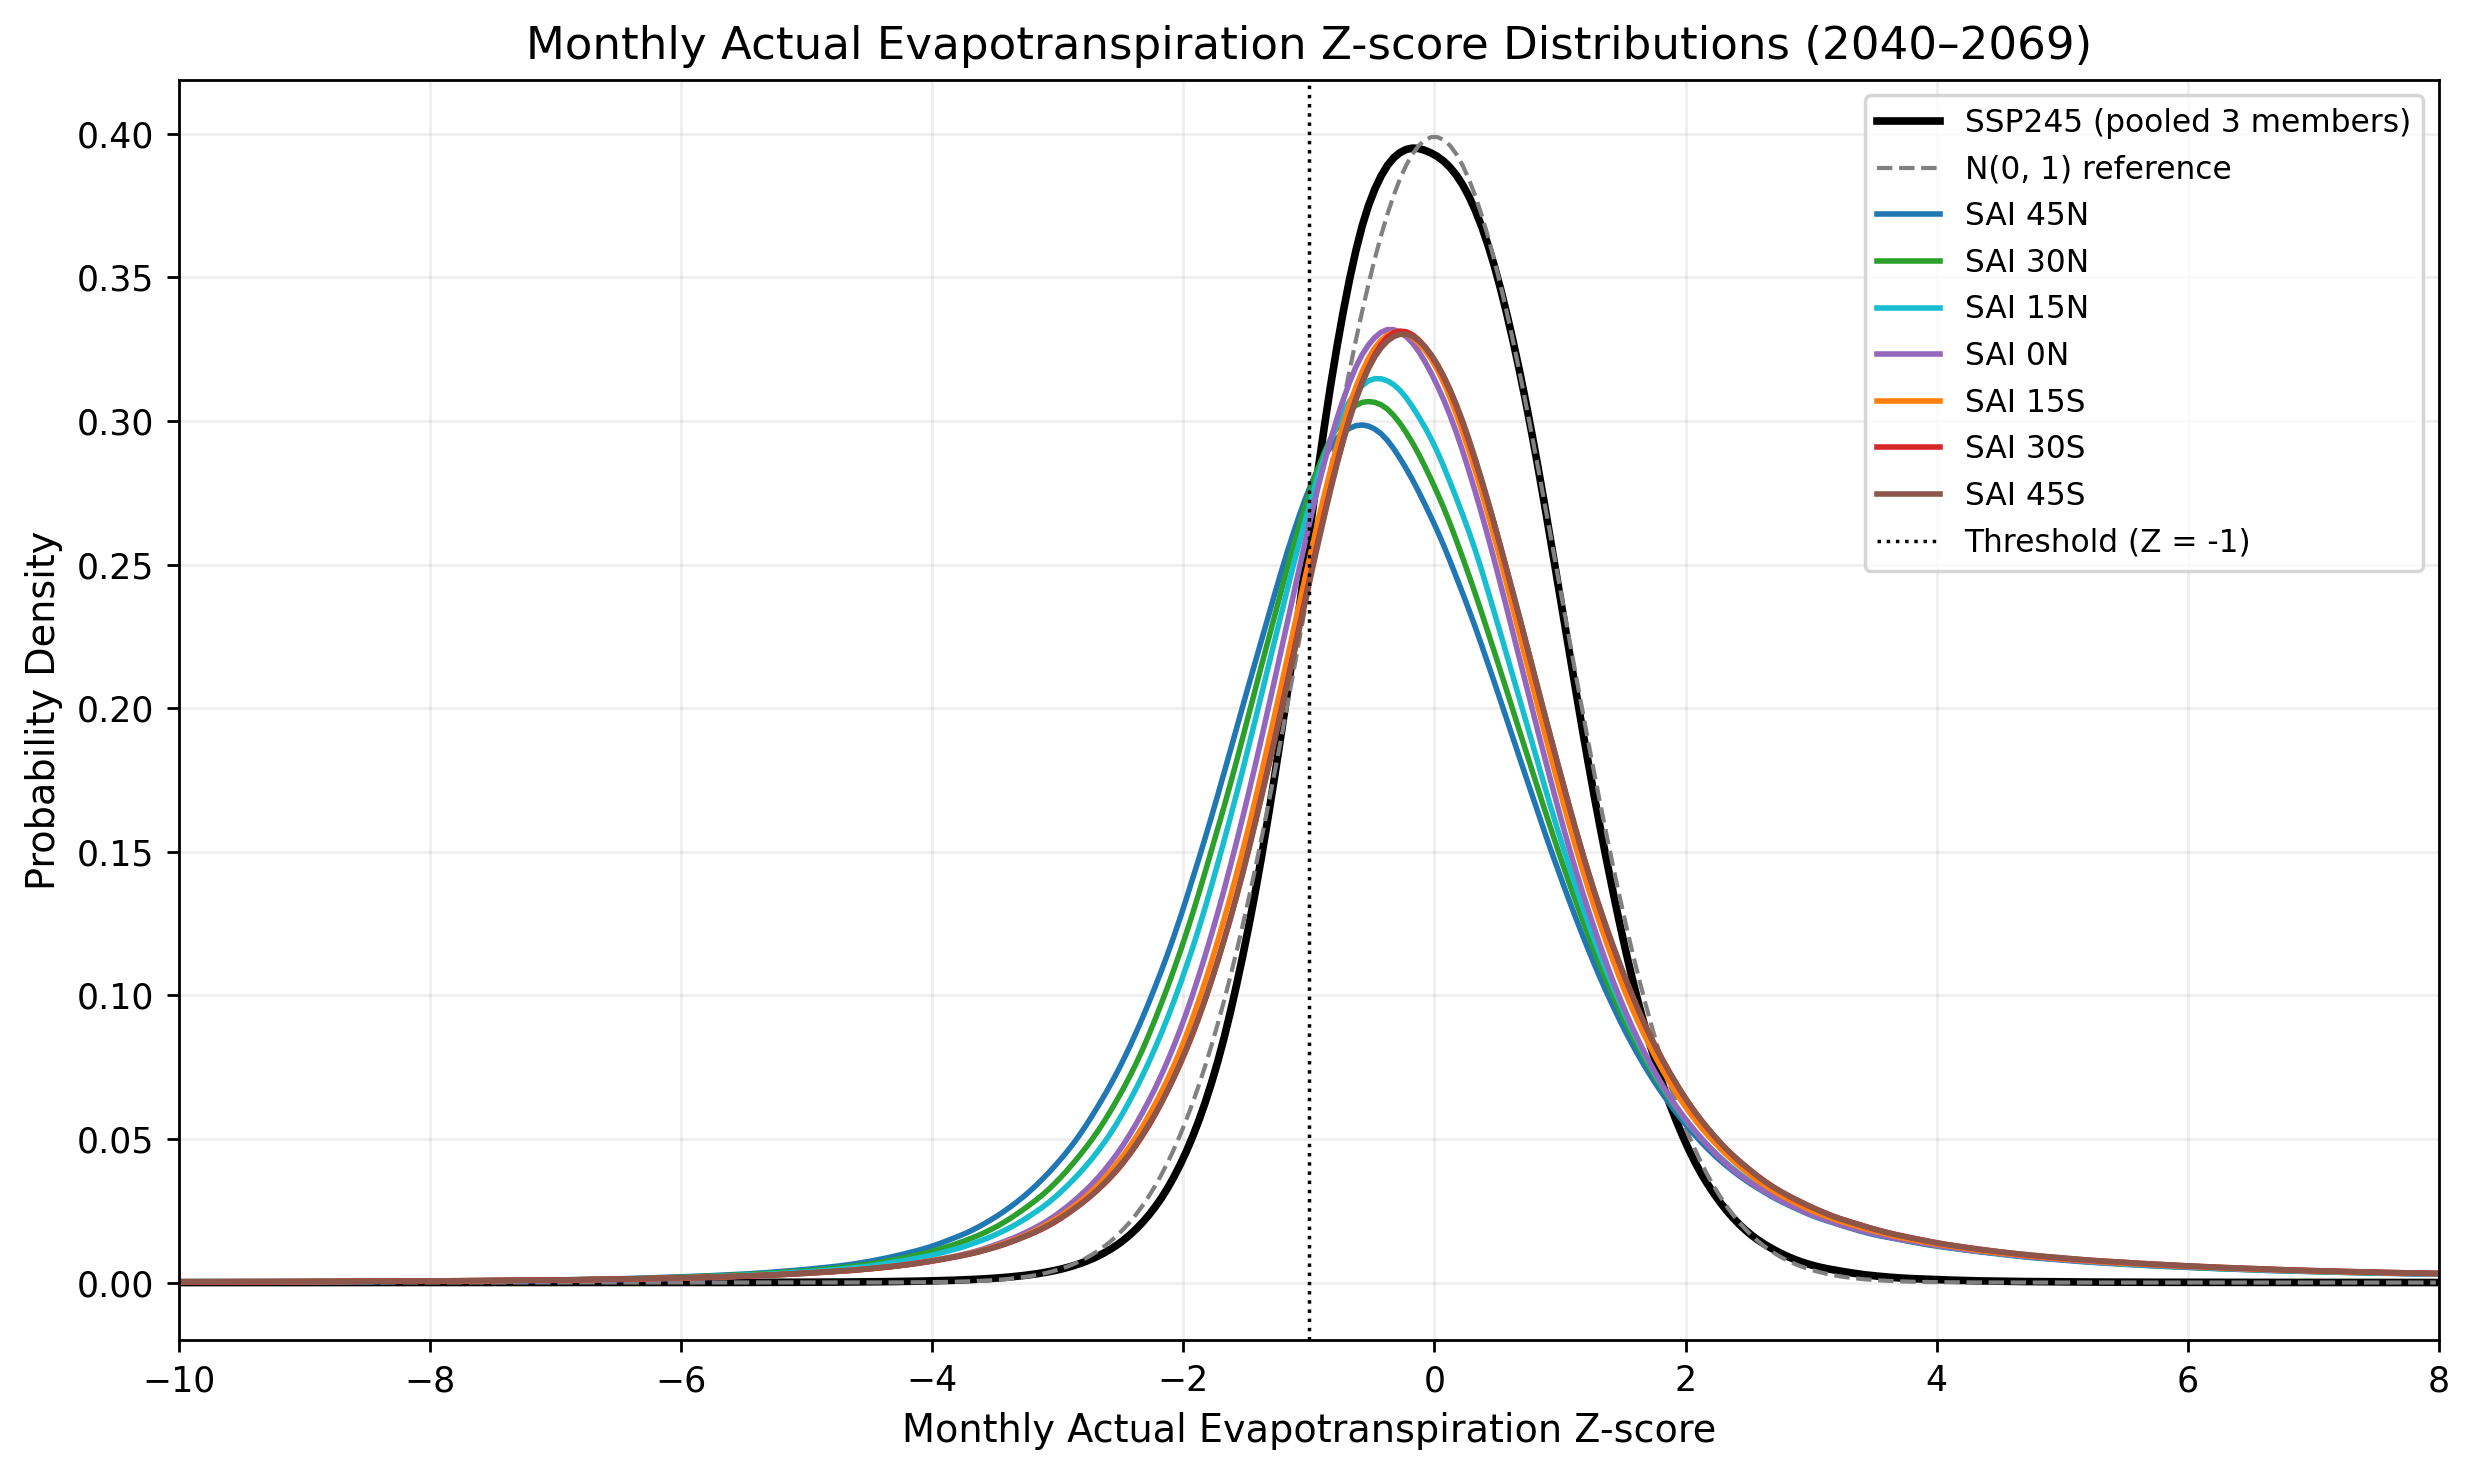


Saved: C:\Users\soyoo\URP_cdo_data\10~11\1118\AET_monthly_zscore_PDF_pooled3.png


In [16]:

from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm

# ==================================================
# 1. Settings
# ==================================================

BASE_DIR = Path(
    r"C:\Users\soyoo\URP_cdo_data\10~11\1118"
)

DATA_DIR = BASE_DIR / "AET_zscore_pooled3"

OUTPUT_PNG = BASE_DIR / "AET_monthly_zscore_PDF_pooled3.png"

scenarios = [
    "45N", "30N", "15N", "0N",
    "15S", "30S", "45S"
]

sai_members = [
    "e02", "e03", "e04",
    "e05", "e06", "e07"
]

ssp_members = [
    "r1", "r2", "r3"
]

palette = {
    "45N": "#1F77B4",
    "30N": "#2CA02C",
    "15N": "#17BECF",
    "0N":  "#9467BD",
    "15S": "#FF7F0E",
    "30S": "#D62728",
    "45S": "#8C564B",
}

XMIN = -10.0
XMAX = 8.0
BIN_WIDTH = 0.05
SMOOTH_SIGMA = 1.5

edges = np.arange(
    XMIN,
    XMAX + BIN_WIDTH / 2,
    BIN_WIDTH
)

centers = (
    edges[:-1] + edges[1:]
) / 2

# ==================================================
# 2. Load common spatial mask
# ==================================================

MASK_CANDIDATES = [
    BASE_DIR / "common_spatial_mask.npy",
    BASE_DIR.parent / "1115" / "common_spatial_mask.npy",
]

mask_path = next(
    (p for p in MASK_CANDIDATES if p.is_file()),
    None
)

if mask_path is None:
    raise FileNotFoundError(
        "common_spatial_mask.npy not found "
        "in 1118 or 1115."
    )

mask = np.load(mask_path).astype(bool)

if mask.shape != (192, 288):
    raise ValueError(
        f"Unexpected mask shape: {mask.shape}"
    )

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Data directory not found: {DATA_DIR}"
    )

print("Mask:", mask_path)
print("Valid grid cells:", mask.sum())
print("Z-score directory:", DATA_DIR)

# ==================================================
# 3. Read valid monthly z-score values
# ==================================================

def load_valid_values(path):

    if not path.is_file():
        raise FileNotFoundError(path)

    with xr.open_dataset(path) as ds:

        # Prefer 'aet' variable
        if "aet" in ds.data_vars:
            variable = "aet"
        else:
            candidates = [
                name
                for name in ds.data_vars
                if set(
                    ("time", "lat", "lon")
                ).issubset(ds[name].dims)
            ]

            if len(candidates) != 1:
                raise ValueError(
                    f"Cannot uniquely identify AET variable: {path}"
                )

            variable = candidates[0]

        da = ds[variable].transpose(
            "time", "lat", "lon"
        )

        if da.sizes["time"] != 360:
            raise ValueError(
                f"Expected 360 months: {path}"
            )

        if tuple(da.shape[1:]) != mask.shape:
            raise ValueError(
                f"Grid mismatch: {path}"
            )

        expected_years = np.repeat(
            np.arange(2040, 2070), 12
        )

        expected_months = np.tile(
            np.arange(1, 13), 30
        )

        if not np.array_equal(
            da.time.dt.year.values,
            expected_years
        ):
            raise ValueError(
                f"Unexpected year sequence: {path}"
            )

        if not np.array_equal(
            da.time.dt.month.values,
            expected_months
        ):
            raise ValueError(
                f"Unexpected month sequence: {path}"
            )

        values = da.values[:, mask].copy()

    return values[np.isfinite(values)]

# ==================================================
# 4. Build pooled empirical PDF
# ==================================================

def build_pdf(paths):

    counts = np.zeros(
        len(edges) - 1,
        dtype=np.float64
    )

    total = 0
    below_minus_one = 0
    outside_plot = 0

    for path in paths:

        values = load_valid_values(path)

        hist, _ = np.histogram(
            values,
            bins=edges
        )

        counts += hist

        total += values.size

        below_minus_one += np.count_nonzero(
            values < -1.0
        )

        outside_plot += np.count_nonzero(
            (values < XMIN) | (values > XMAX)
        )

        print(
            f"Loaded: {path.name} | "
            f"valid values: {values.size:,}"
        )

    if total == 0:
        raise ValueError(
            "No valid AET observations found."
        )

    # Normalize by total valid observations
    density = counts / (
        total * BIN_WIDTH
    )

    density = gaussian_filter1d(
        density,
        sigma=SMOOTH_SIGMA
    )

    pct_low = (
        100.0 * below_minus_one / total
    )

    pct_outside = (
        100.0 * outside_plot / total
    )

    return density, pct_low, pct_outside

# ==================================================
# 5. SSP245 pooled empirical distribution
# ==================================================

ssp_paths = [
    DATA_DIR / (
        f"AET_zscore_monthly_SSP245_{member}.nc"
    )
    for member in ssp_members
]

print("\n===== SSP245 (3 members) =====")

ssp_density, ssp_low, ssp_tail = build_pdf(
    ssp_paths
)

# ==================================================
# 6. Plot
# ==================================================

fig, ax = plt.subplots(
    figsize=(10, 6),
    dpi=250
)

ax.plot(
    centers,
    ssp_density,
    color="black",
    linewidth=2.2,
    label="SSP245 (pooled 3 members)"
)

ax.plot(
    centers,
    norm.pdf(centers),
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="N(0, 1) reference"
)

# ==================================================
# 7. SAI scenario PDFs
# ==================================================

print("\n===== SAI SCENARIOS =====")

for scenario in scenarios:

    print(f"\nSAI {scenario}")

    scenario_paths = []

    for member in sai_members:

        path = DATA_DIR / (
            f"AET_zscore_monthly_{scenario}_{member}.nc"
        )

        # Known missing member
        if scenario == "15N" and member == "e05":

            if not path.is_file():
                print(
                    "[Known missing] "
                    "AET 15N e05 skipped."
                )
                continue

        if not path.is_file():
            raise FileNotFoundError(
                f"Missing file: {path}"
            )

        scenario_paths.append(path)

    density, low, tail = build_pdf(
        scenario_paths
    )

    ax.plot(
        centers,
        density,
        color=palette[scenario],
        linewidth=1.6,
        label=f"SAI {scenario}"
    )

    print(
        f"SAI {scenario} "
        f"(n={len(scenario_paths)} members): "
        f"Z < -1 = {low:.2f}%, "
        f"outside plot = {tail:.2f}%"
    )

print(
    f"\nSSP245: "
    f"Z < -1 = {ssp_low:.2f}%, "
    f"outside plot = {ssp_tail:.2f}%"
)

# ==================================================
# 8. Formatting
# ==================================================

ax.axvline(
    -1.0,
    color="black",
    linestyle=":",
    linewidth=1.0,
    label="Threshold (Z = -1)"
)

ax.set_xlim(
    XMIN,
    XMAX
)

ax.set_xlabel(
    "Monthly Actual Evapotranspiration Z-score",
    fontsize=11
)

ax.set_ylabel(
    "Probability Density",
    fontsize=11
)

ax.set_title(
    "Monthly Actual Evapotranspiration "
    "Z-score Distributions (2040–2069)",
    fontsize=13
)

ax.grid(alpha=0.2)

ax.legend(
    fontsize=9,
    frameon=True
)

plt.tight_layout()

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", OUTPUT_PNG)


Mask loaded: C:\Users\soyoo\URP_cdo_data\10~11\1115\common_spatial_mask.npy
Valid grid cells: 11856

Processing SAI 45N
Loaded: PR_zscore_yseasmean_45N_e02.nc
Loaded: PR_zscore_yseasmean_45N_e03.nc
Loaded: PR_zscore_yseasmean_45N_e04.nc
Loaded: PR_zscore_yseasmean_45N_e05.nc
Loaded: PR_zscore_yseasmean_45N_e06.nc
Loaded: PR_zscore_yseasmean_45N_e07.nc

Processing SAI 45S
Loaded: PR_zscore_yseasmean_45S_e02.nc
Loaded: PR_zscore_yseasmean_45S_e03.nc
Loaded: PR_zscore_yseasmean_45S_e04.nc
Loaded: PR_zscore_yseasmean_45S_e05.nc
Loaded: PR_zscore_yseasmean_45S_e06.nc
Loaded: PR_zscore_yseasmean_45S_e07.nc


C:\Users\soyoo\anaconda3\Lib\site-packages\cartopy\mpl\geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
C:\Users\soyoo\anaconda3\Lib\site-packages\cartopy\mpl\geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


45N DJF: mean=-0.297, min=-2.852, max=+16.704
45N MAM: mean=-0.276, min=-2.776, max=+3.775
45N JJA: mean=+0.004, min=-3.164, max=+14.497


C:\Users\soyoo\anaconda3\Lib\site-packages\cartopy\mpl\geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
C:\Users\soyoo\anaconda3\Lib\site-packages\cartopy\mpl\geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
C:\Users\soyoo\anaconda3\Lib\site-packages\cartopy\mpl\geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


45N SON: mean=-0.105, min=-2.616, max=+6.515
45S DJF: mean=-0.032, min=-2.815, max=+11.854


C:\Users\soyoo\anaconda3\Lib\site-packages\cartopy\mpl\geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
C:\Users\soyoo\anaconda3\Lib\site-packages\cartopy\mpl\geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


45S MAM: mean=-0.004, min=-2.842, max=+4.397
45S JJA: mean=+0.004, min=-3.315, max=+8.005


C:\Users\soyoo\anaconda3\Lib\site-packages\cartopy\mpl\geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)


45S SON: mean=-0.077, min=-3.434, max=+5.012


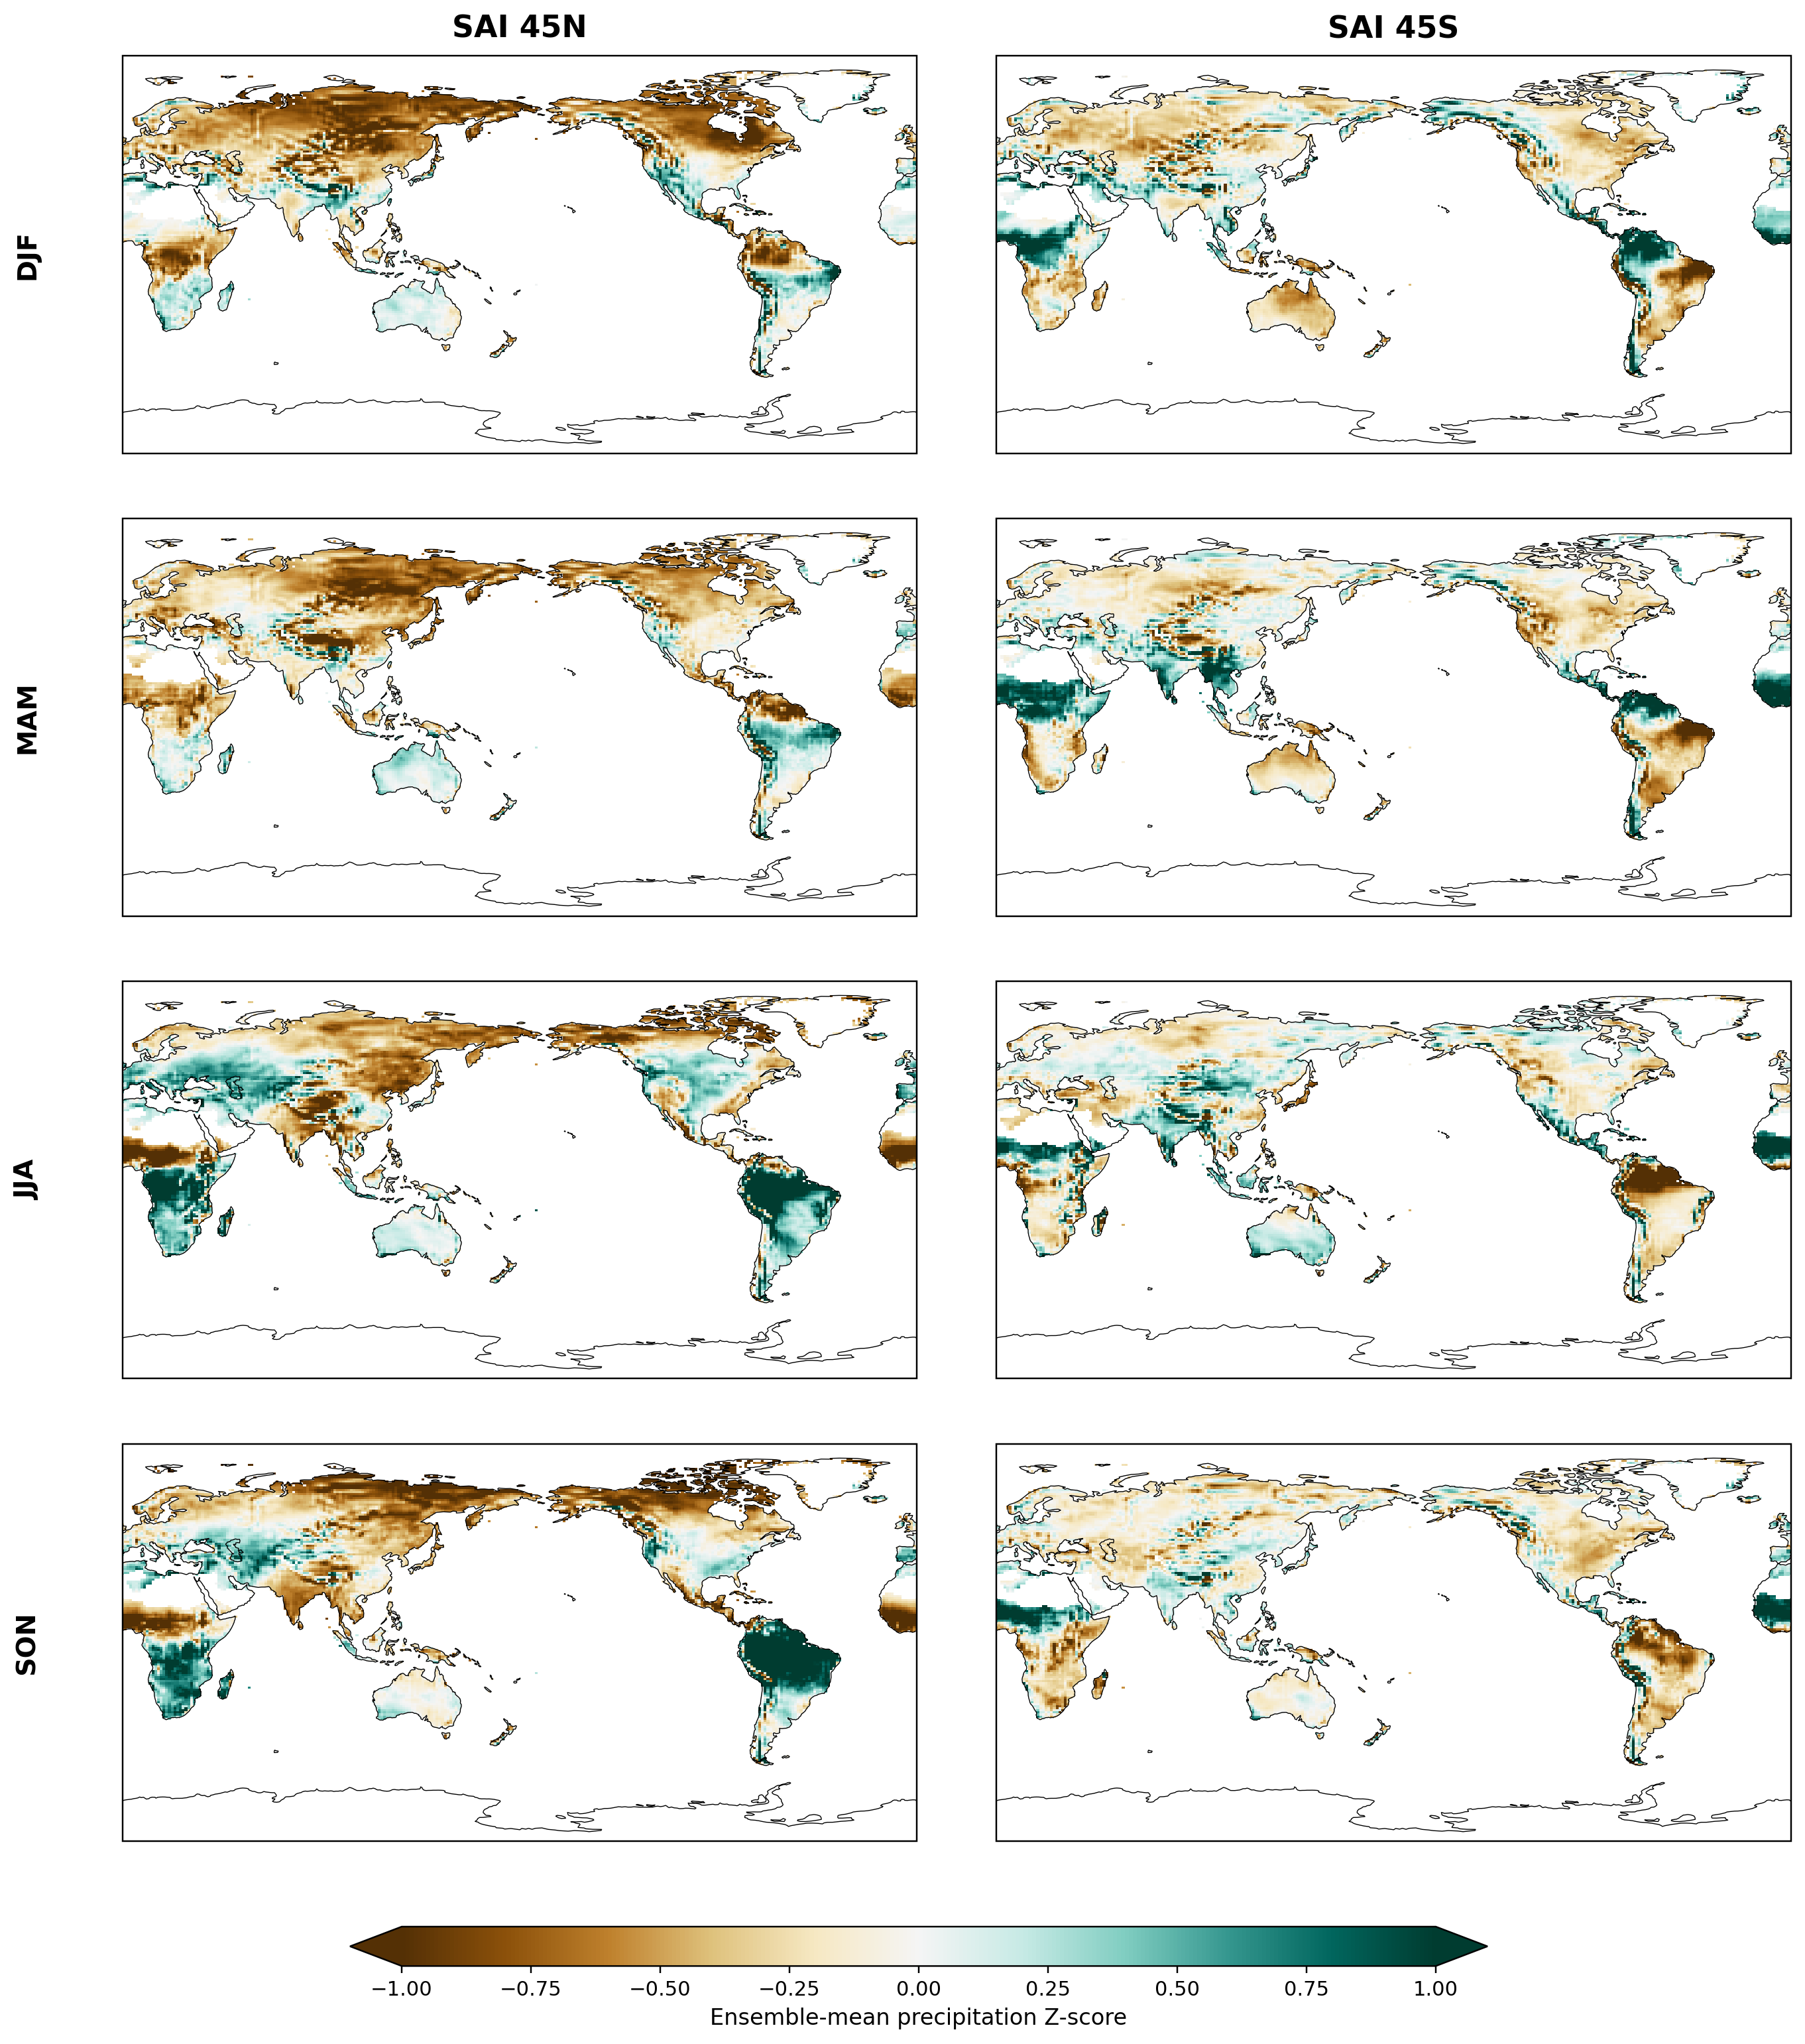


Saved: C:\Users\soyoo\URP_cdo_data\10~11\1118\PR_45N_vs_45S_seasonal_zscore_pooled5.png


In [17]:

from pathlib import Path
import math
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ============================================================
# 1. SETTINGS
# ============================================================

BASE_DIR = Path(
    r"C:\Users\soyoo\URP_cdo_data\10~11\1118"
)

DATA_DIR = BASE_DIR / "PR_zscore_pooled5"

OUTPUT_PNG = (
    BASE_DIR / "PR_45N_vs_45S_seasonal_zscore_pooled5.png"
)

SCENARIOS = ["45N", "45S"]
MEMBERS = ["e02", "e03", "e04", "e05", "e06", "e07"]
SEASONS = ["DJF", "MAM", "JJA", "SON"]

VMIN = -1.0
VMAX = 1.0

# 기존 지도와 동일한 색상
CMAP = "BrBG"

# 해칭: 6개 중 4개 이상 같은 부호
DRAW_HATCHING = False
HATCH_AGREEMENT = 2 / 3

plt.rcParams["hatch.linewidth"] = 0.35
plt.rcParams["hatch.color"] = "#333333"

# ============================================================
# 2. LOAD COMMON SPATIAL MASK
# ============================================================

MASK_CANDIDATES = [
    BASE_DIR / "common_spatial_mask.npy",
    BASE_DIR.parent / "1115" / "common_spatial_mask.npy"
]

mask_path = next(
    (p for p in MASK_CANDIDATES if p.is_file()),
    None
)

if mask_path is None:
    raise FileNotFoundError(
        "common_spatial_mask.npy not found in 1118 or 1115"
    )

mask = np.load(mask_path).astype(bool)

if mask.shape != (192, 288):
    raise ValueError(
        f"Unexpected mask shape: {mask.shape}"
    )

print("Mask loaded:", mask_path)
print("Valid grid cells:", mask.sum())

# ============================================================
# 3. REFERENCE GRID
# ============================================================

reference_file = (
    BASE_DIR / "PR_SSP_yseasmean_pooled5.nc"
)

if not reference_file.exists():
    raise FileNotFoundError(reference_file)

with xr.open_dataset(reference_file) as ds:
    lats = ds["lat"].values.copy()
    lons = ds["lon"].values.copy()

if (len(lats), len(lons)) != mask.shape:
    raise ValueError(
        "Reference grid does not match spatial mask"
    )

# ============================================================
# 4. READ SEASONAL Z-SCORE
# ============================================================

def read_seasonal_zscore(path):

    if not path.exists():
        raise FileNotFoundError(path)

    with xr.open_dataset(path) as ds:

        if "pr" not in ds:
            raise ValueError(
                f"Variable pr not found: {path}"
            )

        da = ds["pr"].transpose(
            "time", "lat", "lon"
        )

        np.testing.assert_allclose(
            da["lat"].values, lats
        )

        np.testing.assert_allclose(
            da["lon"].values, lons
        )

        labels = da.time.dt.season.values

        indices = []

        for season in SEASONS:

            matching = np.where(
                labels == season
            )[0]

            if len(matching) != 1:
                raise ValueError(
                    f"Invalid season {season}: {path}"
                )

            indices.append(matching[0])

        arr = da.values[indices].astype(
            np.float32, copy=True
        )

    if arr.shape != (4, 192, 288):
        raise ValueError(
            f"Unexpected data shape: {arr.shape}"
        )

    arr[~np.isfinite(arr)] = np.nan

    return arr

# ============================================================
# 5. CALCULATE ENSEMBLE MEANS
# ============================================================

scenario_results = {}

for scenario in SCENARIOS:

    print(f"\nProcessing SAI {scenario}")

    member_arrays = []

    for member in MEMBERS:

        file_path = DATA_DIR / (
            f"PR_zscore_yseasmean_{scenario}_{member}.nc"
        )

        arr = read_seasonal_zscore(file_path)

        member_arrays.append(arr)

        print("Loaded:", file_path.name)

    stack = np.stack(
        member_arrays, axis=0
    )

    valid_count = np.sum(
        np.isfinite(stack), axis=0
    )

    ensemble_mean = np.divide(
        np.nansum(stack, axis=0),
        valid_count,
        out=np.full(
            stack.shape[1:],
            np.nan,
            dtype=np.float32
        ),
        where=valid_count > 0
    )

    # Calculate sign agreement
    positive = np.sum(stack > 0, axis=0)
    negative = np.sum(stack < 0, axis=0)

    required = math.ceil(
        HATCH_AGREEMENT * len(MEMBERS)
    )

    hatching = (
        (np.maximum(positive, negative) >= required)
        & (valid_count == len(MEMBERS))
        & mask[None, :, :]
    )

    ensemble_mean = np.where(
        mask[None, :, :],
        ensemble_mean,
        np.nan
    )

    scenario_results[scenario] = {
        "mean": ensemble_mean,
        "hatching": hatching,
        "members": len(MEMBERS)
    }

# ============================================================
# 6. DRAW 4 x 2 MAP
# ============================================================

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(13, 15),
    dpi=220,
    subplot_kw={
        "projection": ccrs.PlateCarree(
            central_longitude=180
        )
    }
)

cmap = plt.get_cmap(CMAP).copy()
cmap.set_bad("white")

norm = mcolors.Normalize(
    vmin=VMIN,
    vmax=VMAX
)

for col, scenario in enumerate(SCENARIOS):

    result = scenario_results[scenario]

    for row, season in enumerate(SEASONS):

        ax = axes[row, col]

        values = result["mean"][row]

        im = ax.pcolormesh(
            lons,
            lats,
            np.clip(values, VMIN, VMAX),
            cmap=cmap,
            norm=norm,
            transform=ccrs.PlateCarree(),
            shading="auto",
            rasterized=True
        )

        if DRAW_HATCHING:

            hatch = result["hatching"][row]

            ax.contourf(
                lons,
                lats,
                hatch.astype(int),
                levels=[0.5, 1.5],
                colors="none",
                hatches=["///"],
                transform=ccrs.PlateCarree()
            )

        ax.add_feature(
            cfeature.COASTLINE,
            linewidth=0.45,
            edgecolor="black"
        )

        ax.set_global()

        if row == 0:
            ax.set_title(
                f"SAI {scenario}",
                fontsize=15,
                fontweight="bold",
                pad=9
            )

        if col == 0:
            ax.text(
                -0.12,
                0.5,
                season,
                transform=ax.transAxes,
                rotation=90,
                va="center",
                ha="center",
                fontsize=13,
                fontweight="bold"
            )

        # Diagnostics
        valid_values = values[
            np.isfinite(values)
        ]

        print(
            f"{scenario} {season}: "
            f"mean={np.mean(valid_values):+.3f}, "
            f"min={np.min(valid_values):+.3f}, "
            f"max={np.max(valid_values):+.3f}"
        )

# ============================================================
# 7. LAYOUT & COLORBAR
# ============================================================

fig.subplots_adjust(
    left=0.08,
    right=0.96,
    top=0.94,
    bottom=0.12,
    wspace=0.10,
    hspace=0.14
)

cax = fig.add_axes(
    [0.20, 0.065, 0.60, 0.018]
)

cbar = fig.colorbar(
    im,
    cax=cax,
    orientation="horizontal",
    extend="both"
)

cbar.set_ticks(
    [-1, -0.75, -0.5, -0.25, 0,
     0.25, 0.5, 0.75, 1]
)

cbar.set_label(
    "Ensemble-mean precipitation Z-score",
    fontsize=11
)

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:", OUTPUT_PNG)
